Удается ли построить классификатор для того поступил/не поступил (Оригинал)

Кластеризовать студентов по их баллам иерархической кластеризацией а) стремясь выделить шарообразные кластеры б) стремясь выделить ленточные (вытянутые) кластеры. Какие при этом брать расстояния? Какое число кластеров взять?

# **DBScan**
ленточные кластеры

DF       Оценка.1  Оценка.2  Оценка.3  Оценка.4  ГТО.оценка  Сочинение.оценка  \
0     1.355916  1.117689  1.176805  0.986485     0.00000          1.195545   
1     1.016937  1.189030  0.941444  0.986485     0.00000          0.000000   
2     0.813550  1.093908  1.129733  1.121005     0.00000          0.597772   
3     1.355916  1.093908  1.176805  0.919224     0.00000          0.597772   
6     1.355916  1.093908  0.917908  0.952854     0.00000          1.195545   
...        ...       ...       ...       ...         ...               ...   
1469  0.949141  1.070127  1.059125  0.896804     0.00000          1.195545   
1470  1.084733  1.022566  1.059125  0.896804     0.00000          0.597772   
1471  0.406775  0.903663  0.941444  1.076165     0.00000          1.195545   
1472  0.677958  0.927444  0.823764  0.874384     6.38326          0.597772   
1473  0.474571  1.046347  0.941444  0.773494     0.00000          1.195545   

      Аттестат.с.отличием.оценка  Оригинал.  
0             

/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


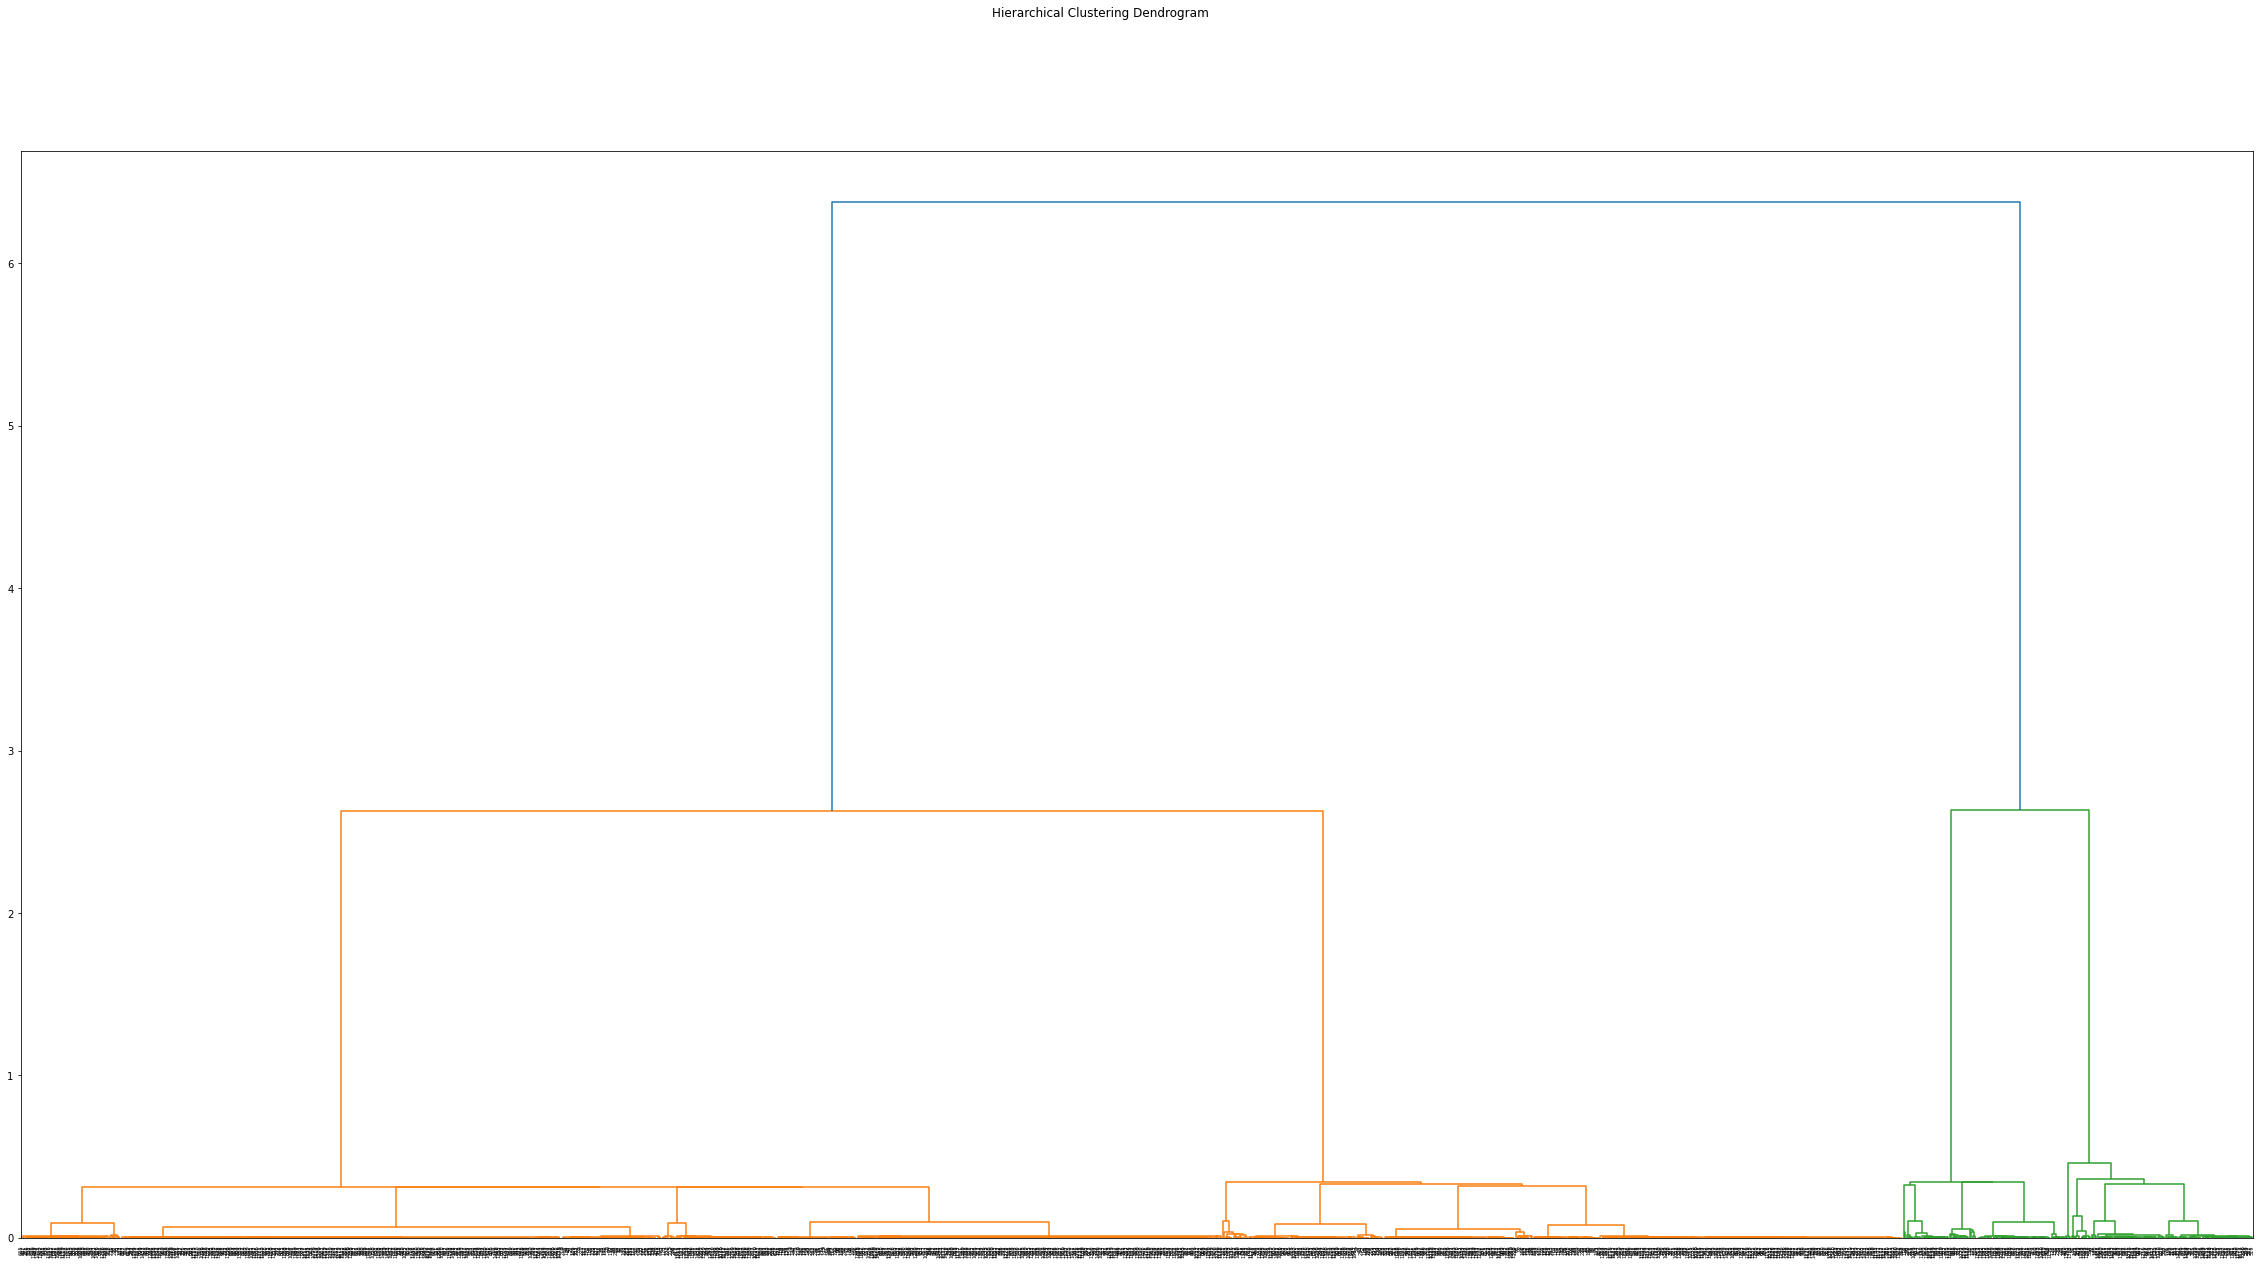

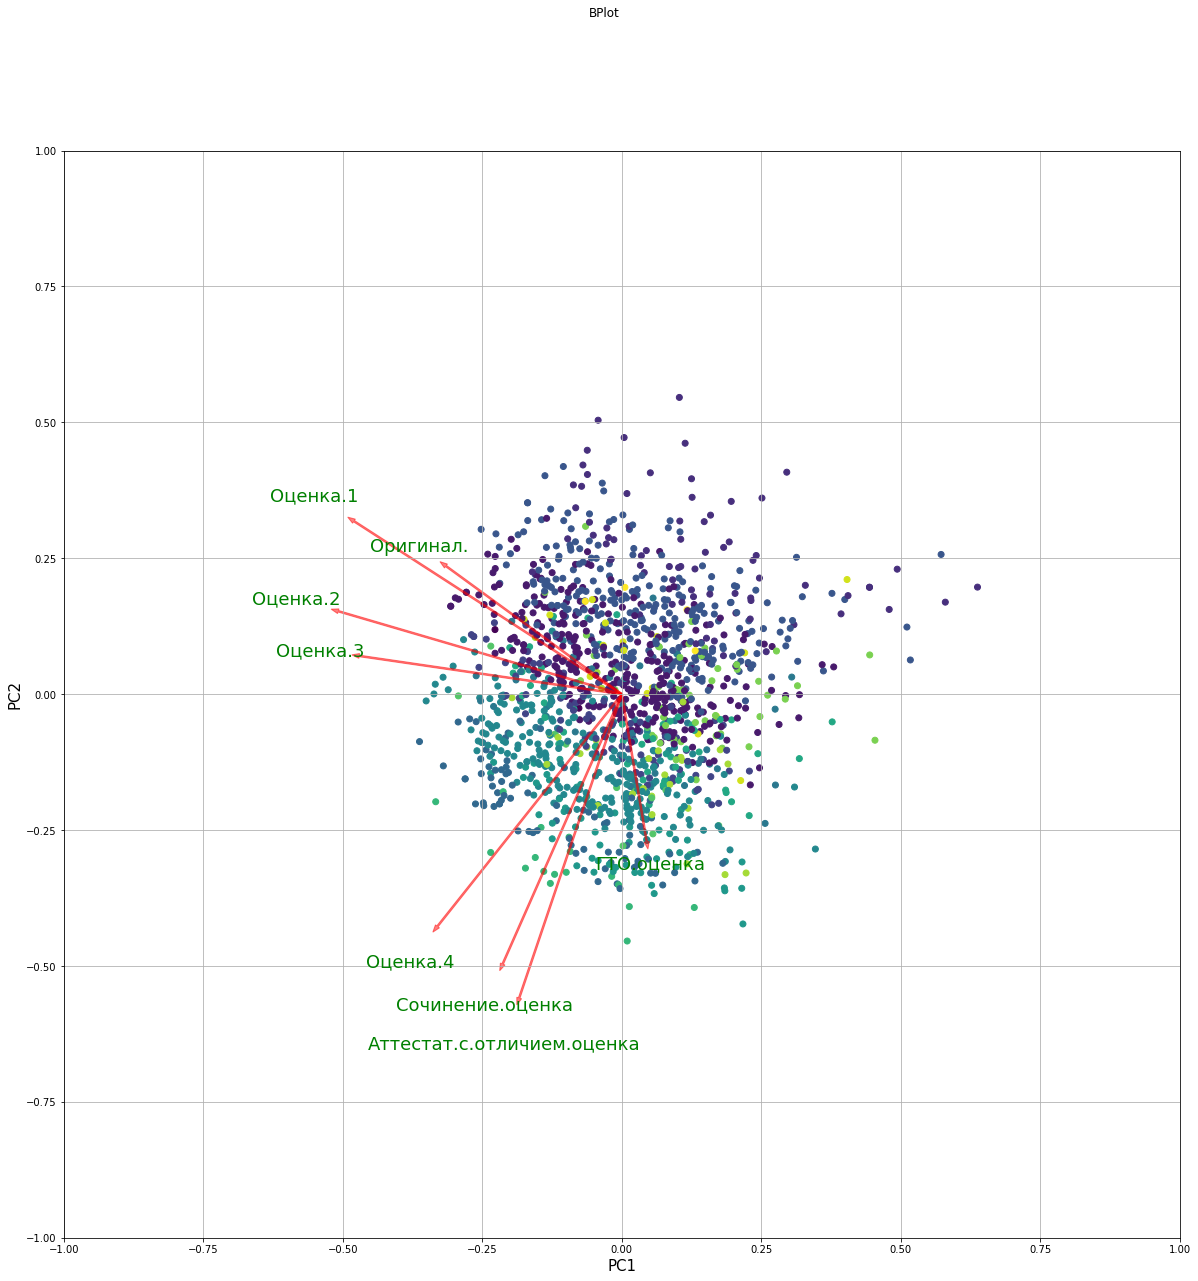

In [ ]:
from numpy.ma.extras import median
import pandas as pd
import numpy as np
import seaborn as sb
from scipy import stats
import matplotlib.pyplot as plt
from joblib import PrintTime
from sklearn.cluster import KMeans, dbscan
from sklearn.cluster import DBSCAN
from sklearn.cluster import OPTICS
from sklearn.cluster import SpectralClustering
from scipy.cluster import hierarchy
from joblib import PrintTime
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import pandas as pd
from sklearn.preprocessing import StandardScaler
import statistics

#удаётся построить классификатор, хорошие значения объяснённой дисперсии для компонент




main_df=pd.read_csv('https://raw.githubusercontent.com/zzzf64/AD/main/data3.csv',delimiter=',')
#print(main_df)
df=pd.DataFrame(main_df,columns=['Оценка.1','Оценка.2','Оценка.3','Оценка.4','ГТО.оценка','Сочинение.оценка','Аттестат.с.отличием.оценка','Оригинал.'])
df['Оригинал.']=df['Оригинал.'].astype(int)
df=df.dropna(axis='index',how='any')
#print(df)
#нормируем, всё на среднее
df['Оценка.1']=df['Оценка.1']/np.mean(df['Оценка.1'])
df['Оценка.2']=df['Оценка.2']/np.mean(df['Оценка.2'])
df['Оценка.3']=df['Оценка.3']/np.mean(df['Оценка.3'])
df['Оценка.4']=df['Оценка.4']/np.mean(df['Оценка.4'])
df['ГТО.оценка']=df['ГТО.оценка']/np.mean(df['ГТО.оценка'])
df['Сочинение.оценка']=df['Сочинение.оценка']/np.mean(df['Сочинение.оценка'])

df['Аттестат.с.отличием.оценка']=df['Аттестат.с.отличием.оценка']/np.mean(df['Аттестат.с.отличием.оценка'])
print('DF',df)



train=df.sample(frac=0.67)
test=df.drop(train.index)

X_t=pd.DataFrame(train,columns=['Оценка.1','Оценка.2','Оценка.3','Оценка.4','ГТО.оценка','Сочинение.оценка','Аттестат.с.отличием.оценка'])
Y_t=pd.DataFrame(train,columns=['Оригинал.'])
X_c=pd.DataFrame(test,columns=['Оценка.1','Оценка.2','Оценка.3','Оценка.4','ГТО.оценка','Сочинение.оценка','Аттестат.с.отличием.оценка'])
Y_c=pd.DataFrame(test,columns=['Оригинал.'])
clf=LDA()
clf.fit(X_t,Y_t)
#print('shape ', Y_c.shape)
#print('classification real ',Y_c)
#print('classification predict ',clf.predict(X_c))
print('accuracy ',clf.score(X_c,Y_c))




print('---')
#разбиваем на 8 компонент
pca=PCA(n_components=8).fit(df)


print(pca.explained_variance_ratio_) # объясненная дисперсия. то есть для каждой компоненты она считает дисперсию
#если мы посмотрим результаты, то увидим что первые 2 компоненты ( 0.71 и 0.21) дают 92% - это "очень хорошо",
#дисперсия не разбросана по всем компонентам, а собрана в 2 и эти 2 компоненты и есть классификатор
#у нас есть оценки(8), эта штука(классификатор) составляет 8 компонент, эти новые компоненты,
#каждая из них - линейная комбинация из старых компонент. Что показывают главные 2 компоненты?
#мы измеряем их "важность" по объясненной дисперсии, получается что по осям этих компонент можно раскладывать,
#они являются класификатором (по линейной комбинации первых двух можно всё построить),
#зная численно чему равны эти компоненты можно нарисовать точку на графике

#они показывают, насколько точно приближают то что нам нужно, насколько точно каждая точка
#может быть представлена этим вектором


#классификатор удалось построить хорошо


print(pca.singular_values_) #сингулярные значeния

print(pca.components_)#\ масив из масивов. 1ый массив,
#состоит из коэффициентов линейной комбинации разложения первой главной компоненты по оценкам
#(по остальным векторам)


A=np.array(pca.components_)
B=np.array(df)
B=np.transpose(B)
C=A@B
#print(C)

D=C[0:3]
#print(D)
D=np.transpose(D)

Z = hierarchy.linkage(D,'single') #single,complete,average,weighted,centroid,median,ward
fig=plt.figure(1,figsize=(40,20))
#строим иерархическую дендограмму
#дендаграмма нам нужна чтобы понять на сколько кластеров нам надо разбивать \
fig.suptitle('Hierarchical Clustering Dendrogram')
dn=hierarchy.dendrogram(Z)
#plt.savefig("dendogram",bbox_inches='tight', dpi=200)


categories=df.columns
fig=plt.figure(2,figsize=(20,20))
fig.suptitle('BPlot')
X=df
y=DBSCAN(eps=0.3, min_samples=4).fit_predict(D) #иерархический алгоритм для получения ленточных классов
#y=OPTICS(min_samples=4).fit_predict(D) # иерархический алгоритм для получения шарообразных классов

# в дбскане нужно указывать расстояние и мин кол-во кластеров, в оптиксе только кол-во кластеров

scaler = StandardScaler()
scaler.fit(X)
X=scaler.transform(X)
#pca = PCA()
x_new = pca.fit_transform(X)

def myplot(score,coeff,labels=None):
    xs = score[:,0]
    ys = score[:,1]
    #xs=D[:,0]
    #ys=D[:,2]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex,ys * scaley,c=y) #c=y
    for i in range(n):
        plt.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'r',alpha = 0.5,width=0.003)
        if labels is None:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, "Var"+str(i+1), color = 'g', ha = 'center', va = 'center',fontsize=18)
        else:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, labels[i], color = 'g', ha = 'center', va = 'center',fontsize=18)
    plt.xlim(-1,1)
    plt.ylim(-1,1)
    plt.xlabel("PC{}".format(1),fontsize=15)
    plt.ylabel("PC{}".format(2),fontsize=15)
    plt.grid()

#Call the function. Use only the 2 PCs.
myplot(x_new[:,0:2],np.transpose(pca.components_[0:2, :]),labels=categories)
plt.savefig("biplot",bbox_inches='tight', dpi=200)



По дендограмме определяем расстояние (0.3) и количество кластеров (4)).

Построим ленточные кластеры с помощью метода DBScan. Получается проекция восьмимерного графика на плоскость.

# **Optics**

<Figure size 2880x1440 with 0 Axes>

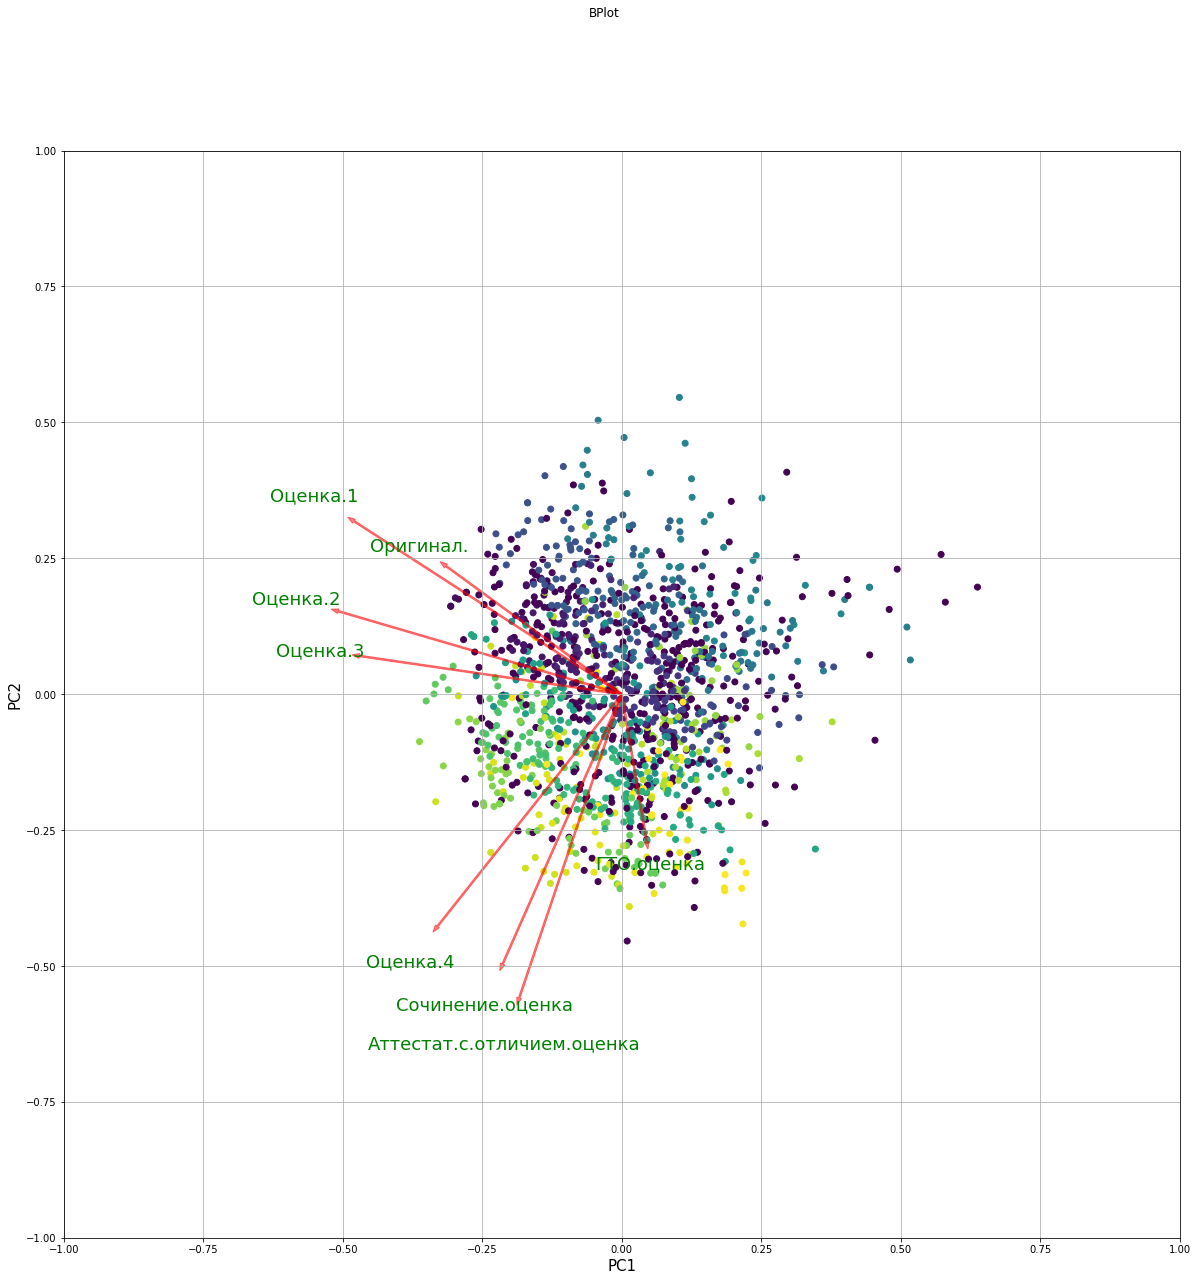

In [ ]:
from numpy.ma.extras import median
import pandas as pd
import numpy as np
import seaborn as sb
from scipy import stats
import matplotlib.pyplot as plt
from joblib import PrintTime
from sklearn.cluster import KMeans, dbscan
from sklearn.cluster import DBSCAN
from sklearn.cluster import OPTICS
from sklearn.cluster import SpectralClustering
from scipy.cluster import hierarchy
from joblib import PrintTime
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import pandas as pd
from sklearn.preprocessing import StandardScaler
import statistics

main_df=pd.read_csv('https://raw.githubusercontent.com/zzzf64/AD/main/data3.csv',delimiter=',')
#print(main_df)
df=pd.DataFrame(main_df,columns=['Оценка.1','Оценка.2','Оценка.3','Оценка.4','ГТО.оценка','Сочинение.оценка','Аттестат.с.отличием.оценка','Оригинал.'])
df['Оригинал.']=df['Оригинал.'].astype(int)
df=df.dropna(axis='index',how='any')
#print(df)
#нормируем
df['Оценка.1']=df['Оценка.1']/np.mean(df['Оценка.1'])
df['Оценка.2']=df['Оценка.2']/np.mean(df['Оценка.2'])
df['Оценка.3']=df['Оценка.3']/np.mean(df['Оценка.3'])
df['Оценка.4']=df['Оценка.4']/np.mean(df['Оценка.4'])
df['ГТО.оценка']=df['ГТО.оценка']/np.mean(df['ГТО.оценка'])
df['Сочинение.оценка']=df['Сочинение.оценка']/np.mean(df['Сочинение.оценка'])

df['Аттестат.с.отличием.оценка']=df['Аттестат.с.отличием.оценка']/np.mean(df['Аттестат.с.отличием.оценка'])

pca=PCA(n_components=8).fit(df)

A=np.array(pca.components_)
B=np.array(df)
B=np.transpose(B)
C=A@B

D=C[0:3]
D=np.transpose(D)

categories=df.columns
fig=plt.figure(2,figsize=(20,20))
fig.suptitle('BPlot')
X=df
y=OPTICS(min_samples=4).fit_predict(D)
scaler = StandardScaler()
scaler.fit(X)
X=scaler.transform(X)
#pca = PCA()
x_new = pca.fit_transform(X)

def myplot(score,coeff,labels=None):
    xs = score[:,0]
    ys = score[:,1]
    #xs=D[:,0]
    #ys=D[:,2]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex,ys * scaley,c=y) #c=y
    for i in range(n):
        plt.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'r',alpha = 0.5,width=0.003)
        if labels is None:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, "Var"+str(i+1), color = 'g', ha = 'center', va = 'center',fontsize=18)
        else:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, labels[i], color = 'g', ha = 'center', va = 'center',fontsize=18)
    plt.xlim(-1,1)
    plt.ylim(-1,1)
    plt.xlabel("PC{}".format(1),fontsize=15)
    plt.ylabel("PC{}".format(2),fontsize=15)
    plt.grid()

#Call the function. Use only the 2 PCs.
myplot(x_new[:,0:2],np.transpose(pca.components_[0:2, :]),labels=categories)
plt.savefig("biplot",bbox_inches='tight', dpi=200)